# task 3 -> test-time compute: sampling, selection and adaptive inference

## imports

In [1]:
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#the scripts use paths relative to the repo root (configs/, data/, results/), so the notebook runs from there
if not Path('configs').exists():
    os.chdir('..')

from common.utils import load_yaml, read_jsonl, repo_path

## global env variables ->

In [2]:
#papermill overrides these for the smoke test, the defaults are the real run
CONFIG = 'configs/task3.yaml'
RUN_SCRIPTS = True #False -> only rebuild the tables and figures from results already on disk

In [3]:
# Parameters
CONFIG = "configs/task3.yaml"
RUN_SCRIPTS = False


In [4]:
cfg = load_yaml(CONFIG)
RESULTS = repo_path(cfg['results_dir'])
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
DATA = repo_path(cfg['data_dir'])
#the exact configuration of this run (smoke overrides included), kept with its results
import yaml
(RESULTS / 'run_config.yaml').write_text(yaml.safe_dump(cfg, sort_keys=False))

DATASETS = list(cfg['datasets']) #math, mathvista
BUDGETS = cfg['budgets']
NAMES = {'math': 'MATH (Qwen2.5-3B)', 'mathvista': 'MathVista (Qwen2.5-VL-3B)'}
#one fixed colour per method, the same in every figure
COLORS = {'first': '#52514e', 'self_consistency': '#2a78d6', 'mean_logp': '#9b9a95', 'self_certainty': '#eb6834',
          'self_certainty_rwc': '#b8441a', 'shortest': '#c9b458', 'vision': '#7fb77e', 'vision_rwc': '#3d8b3c',
          'visconf': '#b48ad6', 'visconf_rwc': '#7a3fb0', 'visconf_token': '#e3a3c6', 'visconf_token_rwc': '#b0507f'}

PYTHON = sys.executable #the interpreter running this notebook, so the scripts use the same environment

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'lines.linewidth': 2})


def run(command):
    #runs one script as its own process, exactly as it would be typed in a terminal. each script writes its results
    #to disk, nothing is passed through notebook state. finished work is skipped
    if RUN_SCRIPTS:
        get_ipython().system(command)
        assert get_ipython().user_ns['_exit_code'] == 0, f'failed -> {command}'


def load_result(name):
    return json.loads((RESULTS / name).read_text())


def eval_only(frame):
    #the reported numbers are on the 800 held-out questions. development numbers stay in the csv files
    return frame[frame['split'] == 'eval']

## 1. data -> join and check the supplied tables, splits, answer groups and correctness
cpu only. downloads ATML-PA3-Data and the mathvista metadata once, verifies token-list alignment, makes the
200 / 800 split (and the 50 live questions), and labels every rollout.

In [5]:
run(f'{PYTHON} -m task3_ttc.prepare_data --config {CONFIG}')
prep = load_result('prepare_summary.json')
print('scorer ->', prep['scorer'])
for d in DATASETS:
    info = prep['datasets'][d]
    assert all(v is True or v == 0 for v in info['checks'].values()), info['checks']
    print(f"{d}: every check passed -> {sorted(info['checks'])}")
display(pd.DataFrame({d: {k: v for k, v in prep['datasets'][d].items() if k != 'checks'} for d in DATASETS}).astype(object))

scorer -> {'math_verify': '0.9.0', 'latex2sympy2_extended': '1.11.0', 'mathvista_rules': 'calculate_score.py normalize_extracted_answer, testmini.json at commit 452b0f8'}
math: every check passed -> ['finite_token_values', 'generated_token_ids_matches_n_generated_text_tokens', 'kl_u_p_matches_n_generated_text_tokens', 'logp_matches_n_generated_text_tokens', 'no_empty_rollout', 'rollouts_0_to_31_per_question', 'rollouts_graded_differently_alone', 'same_keys_in_every_file', 'single_dataset_name']
mathvista: every check passed -> ['attention_preceding_counts_are_0_to_T-1', 'finite_token_values', 'first_prediction_has_zero_generated_attention', 'generated_text_attn_total_matches_n_generated_text_tokens', 'generated_token_ids_matches_n_generated_text_tokens', 'img_attn_total_matches_n_generated_text_tokens', 'kl_u_p_matches_n_generated_text_tokens', 'logp_matches_n_generated_text_tokens', 'mathvista_gold_answers_normalize_to_themselves', 'n_generated_text_tokens (attention)_matches_n_genera

,math,mathvista
questions,1000.0,1000.0
rollouts,32000.0,32000.0
retained_tokens,20742094.0,8961703.0
capped_rollouts,523.0,487.0
null_extractions,521.0,3032.0
unconvertible_extraction_rollouts,0.0,1889.0
unconvertible_groups,0.0,1062.0
multi_choice_similarity_fallbacks,0.0,93.0
rollout_accuracy,0.663156,0.536438
mean_groups_per_question,5.654,4.996


## 2. offline selection and signals (steps 1 to 3)
ten seeded orders per question, budgets N = 1 to 32 as nested prefixes, every selection rule on the same candidates.

In [6]:
run(f'{PYTHON} -m task3_ttc.offline --config {CONFIG}')
summary = pd.read_csv(RESULTS / 'offline_summary.csv')
boot = pd.read_csv(RESULTS / 'offline_bootstrap.csv')
summary_eval = eval_only(summary)

## 3. adaptive sampling (step 5), settings chosen on the development split, then frozen

In [7]:
run(f'{PYTHON} -m task3_ttc.adaptive --config {CONFIG}')

## 4. live generation (step 4), the only gpu step

In [8]:
run(f'{PYTHON} -m task3_ttc.live --config {CONFIG}')

## step 1 -> opportunity from repeated sampling
firstans accuracy, oracle coverage, distinct answer groups (NO_ANSWER counts as a group), and the decomposition of
self-consistency failures into not generated (no correct candidate) and missed (a correct candidate was available).

In [9]:
rows = []
for d in DATASETS:
    s = summary_eval[summary_eval['dataset'] == d].set_index(['N', 'method'])
    for n in BUDGETS:
        sc = s.loc[(n, 'self_consistency')]
        rows.append({'dataset': d, 'N': n, 'firstans_accuracy': s.loc[(n, 'first'), 'accuracy'], 'oracle_coverage': sc['oracle'],
                     'distinct_groups': sc['n_groups'], 'sc_accuracy': sc['accuracy'], 'sc_missed': sc['missed'],
                     'not_generated': sc['not_generated'], 'tokens_all_candidates': sc['cost'],
                     'tokens_firstans': s.loc[(n, 'first'), 'cost']})
step1 = pd.DataFrame(rows)
step1.to_csv(RESULTS / 'table_step1_sampling.csv', index=False)
display(step1.round(4))

,dataset,N,firstans_accuracy,oracle_coverage,distinct_groups,sc_accuracy,sc_missed,not_generated,tokens_all_candidates,tokens_firstans
0,math,1,0.6435,0.6435,1.0000,0.6435,0.0000,0.3565,669.7726,669.7726
1,math,2,0.6435,0.7249,1.3709,0.6435,0.0814,0.2751,1339.8655,669.7726
2,math,4,0.6435,0.7908,1.9278,0.6920,0.0988,0.2092,2679.6941,669.7726
3,math,8,0.6435,0.8435,2.7407,0.7179,0.1256,0.1565,5344.1085,669.7726
4,math,16,0.6435,0.8845,4.0042,0.7311,0.1534,0.1155,10677.7428,669.7726
5,math,32,0.6435,0.9138,5.9050,0.7379,0.1759,0.0863,21347.0175,669.7726
6,mathvista,1,0.5360,0.5360,1.0000,0.5360,0.0000,0.4640,277.7964,277.7964
7,mathvista,2,0.5360,0.6604,1.4534,0.5360,0.1244,0.3396,551.2501,277.7964
8,mathvista,4,0.5360,0.7588,2.0364,0.5799,0.1789,0.2412,1111.5916,277.7964
9,mathvista,8,0.5360,0.8269,2.7856,0.6051,0.2218,0.1731,2229.9020,277.7964


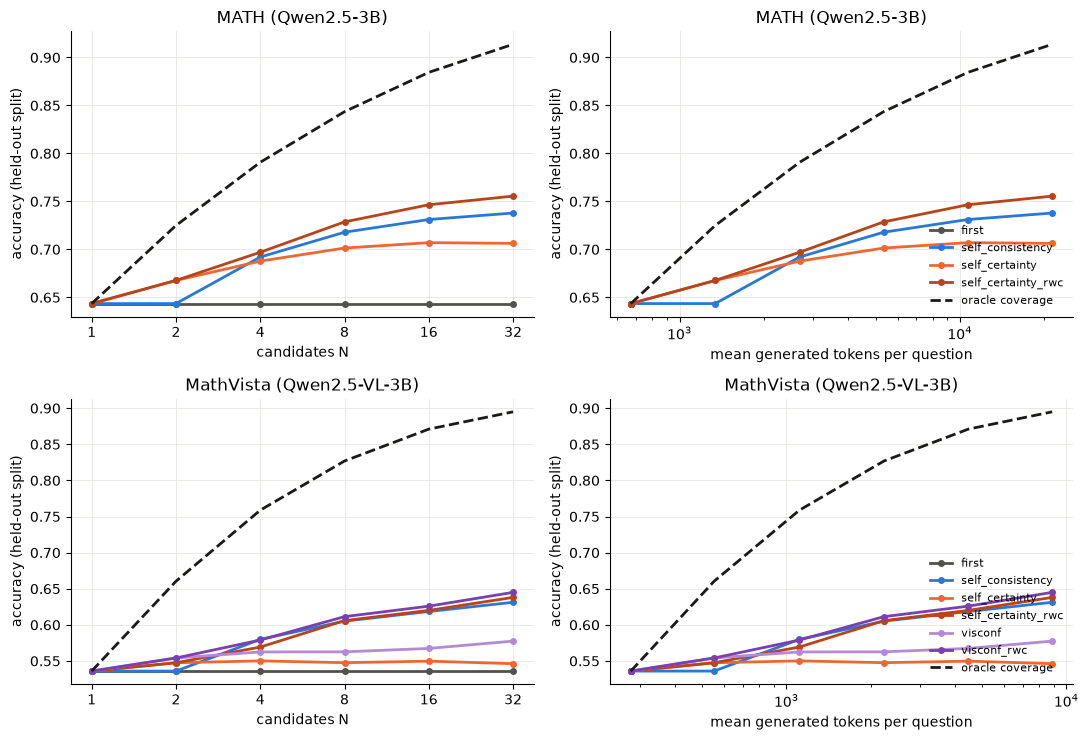

In [10]:
#accuracy and coverage against candidates (left) and generated tokens (right). dashed = oracle coverage
main_methods = ['first', 'self_consistency', 'self_certainty', 'self_certainty_rwc']
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for row, d in enumerate(DATASETS):
    s = summary_eval[summary_eval['dataset'] == d]
    methods = main_methods + (['visconf', 'visconf_rwc'] if d == 'mathvista' else [])
    for col, x in enumerate(['N', 'cost']):
        ax = axes[row, col]
        for m in methods:
            t = s[s['method'] == m]
            ax.plot(t[x], t['accuracy'], marker='o', ms=4, color=COLORS[m], label=m)
        o = s[s['method'] == 'self_consistency']
        ax.plot(o[x], o['oracle'], ls='--', color='#1a1a19', label='oracle coverage')
        ax.set_xscale('log', base=2 if x == 'N' else 10)
        ax.set_xlabel('candidates N' if x == 'N' else 'mean generated tokens per question')
        ax.set_ylabel('accuracy (held-out split)')
        ax.set_title(NAMES[d])
    axes[row, 0].set_xticks(BUDGETS, [str(n) for n in BUDGETS])
axes[0, 1].legend(fontsize=8, frameon=False, loc='lower right')
axes[1, 1].legend(fontsize=8, frameon=False, loc='lower right')
fig.tight_layout()
fig.savefig(FIGURES / 'accuracy_coverage.png', dpi=200)
plt.show()

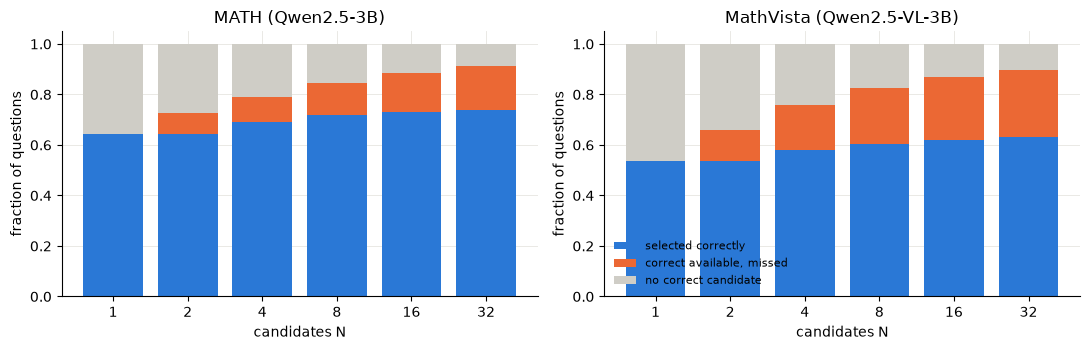

In [11]:
#failure decomposition of self-consistency per budget -> correct, missed (correct candidate available), not generated
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, d in zip(axes, DATASETS):
    t = step1[step1['dataset'] == d]
    x = np.arange(len(t))
    ax.bar(x, t['sc_accuracy'], color='#2a78d6', label='selected correctly')
    ax.bar(x, t['sc_missed'], bottom=t['sc_accuracy'], color='#eb6834', label='correct available, missed')
    ax.bar(x, t['not_generated'], bottom=t['sc_accuracy'] + t['sc_missed'], color='#cfcdc6', label='no correct candidate')
    ax.set_xticks(x, [str(n) for n in t['N']])
    ax.set_xlabel('candidates N')
    ax.set_ylabel('fraction of questions')
    ax.set_title(NAMES[d])
axes[1].legend(fontsize=8, frameon=False, loc='lower left')
fig.tight_layout()
fig.savefig(FIGURES / 'failure_decomposition.png', dpi=200)
plt.show()

## step 2 -> quality scoring and answer aggregation
accuracy of every rule at every budget (held-out split), then paired bootstrap differences (1,000 question resamples).

In [12]:
for d in DATASETS:
    t = summary_eval[summary_eval['dataset'] == d].pivot(index='method', columns='N', values='accuracy')
    t = t.loc[[m for m in COLORS if m in t.index]]
    t.to_csv(RESULTS / f'table_methods_{d}.csv')
    print(NAMES[d])
    display(t.round(4))

MATH (Qwen2.5-3B)


N,1,2,4,8,16,32
method,,,,,,
first,0.6435,0.6435,0.6435,0.6435,0.6435,0.6435
self_consistency,0.6435,0.6435,0.6920,0.7179,0.7311,0.7379
mean_logp,0.6435,0.6580,0.6724,0.6754,0.6639,0.6400
self_certainty,0.6435,0.6676,0.6878,0.7014,0.7070,0.7062
self_certainty_rwc,0.6435,0.6676,0.6970,0.7286,0.7465,0.7555
shortest,0.6435,0.6529,0.6520,0.6456,0.6316,0.6238


MathVista (Qwen2.5-VL-3B)


N,1,2,4,8,16,32
method,,,,,,
first,0.536,0.5360,0.5360,0.5360,0.5360,0.5360
self_consistency,0.536,0.5360,0.5799,0.6051,0.6185,0.6312
mean_logp,0.536,0.5426,0.5324,0.5191,0.5049,0.4812
self_certainty,0.536,0.5475,0.5501,0.5476,0.5498,0.5462
self_certainty_rwc,0.536,0.5475,0.5692,0.6059,0.6200,0.6380
shortest,0.536,0.5498,0.5515,0.5456,0.5430,0.5385
vision,0.536,0.5434,0.5452,0.5432,0.5400,0.5362
vision_rwc,0.536,0.5434,0.5672,0.6046,0.6200,0.6388
visconf,0.536,0.5541,0.5625,0.5626,0.5674,0.5775


In [13]:
#main differences at N = 32 (and the full set for every N in offline_bootstrap.csv)
b = eval_only(boot)
b32 = b[b['N'] == 32].copy()
b32['significant'] = (b32['ci_low'] > 0) | (b32['ci_high'] < 0)
b32.to_csv(RESULTS / 'table_bootstrap_n32.csv', index=False)
display(b32.drop(columns=['split', 'N']).round(4))

,dataset,method,baseline,difference,ci_low,ci_high,significant
32,math,first,self_consistency,-0.0944,-0.1101,-0.0798,True
33,math,mean_logp,self_consistency,-0.0979,-0.1239,-0.0740,True
34,math,self_certainty,self_consistency,-0.0316,-0.0551,-0.0082,True
35,math,self_certainty_rwc,self_consistency,0.0176,0.0069,0.0291,True
36,math,shortest,self_consistency,-0.1141,-0.1413,-0.0899,True
37,math,self_consistency,first,0.0944,0.0798,0.1101,True
38,math,self_certainty_rwc,self_certainty,0.0492,0.0280,0.0718,True
39,math,self_certainty,mean_logp,0.0662,0.0425,0.0912,True
172,mathvista,first,self_consistency,-0.0952,-0.1132,-0.0764,True
173,mathvista,mean_logp,self_consistency,-0.1500,-0.1796,-0.1189,True


## step 3 -> what the signals capture (N = 32)
within-question associations. quartile gap = correctness of the top 8 minus the bottom 8 rollouts by the score,
averaged over questions (mixed = questions with both correct and incorrect rollouts, the only ones where it can
differ from zero). shortest-rollout selection is in the method tables above as the length-only control.

In [14]:
signals = load_result('signals_summary.json')
rows = []
for d in DATASETS:
    s = signals[d]['eval']
    for name, v in s['scores'].items():
        rows.append({'dataset': d, 'score': name, **v})
    print(f"{d}: {s['mixed_questions']} of {s['questions']} questions mixed, mean length correct minus incorrect "
          f"(mixed) = {s['length_correct_minus_incorrect_mixed']:.1f} tokens")
sig_table = pd.DataFrame(rows)
sig_table.to_csv(RESULTS / 'table_signals.csv', index=False)
display(sig_table.round(4))

math: 469 of 800 questions mixed, mean length correct minus incorrect (mixed) = -87.4 tokens
mathvista: 634 of 800 questions mixed, mean length correct minus incorrect (mixed) = -80.1 tokens


,dataset,score,quartile_gap_all,quartile_gap_mixed,correct_minus_incorrect_mixed,spearman_length
0,math,L,0.0783,0.1335,0.0068,0.2245
1,math,K,0.1198,0.2044,0.8109,-0.1611
2,math,length,-0.0459,-0.0784,-87.4306,NaN
3,mathvista,L,0.0159,0.0201,0.0033,0.3290
4,mathvista,K,0.0348,0.0440,0.1089,0.3493
5,mathvista,length,-0.0394,-0.0497,-80.0871,NaN
6,mathvista,V,0.0378,0.0477,0.0019,-0.6858
7,mathvista,Z,0.0739,0.0933,0.0009,-0.2750
8,mathvista,Z_token,0.0723,0.0913,0.0009,-0.3218


In [15]:
#mathvista -> confidence-vision correlation within each rollout (pearson over its tokens), averaged per question,
#then summarized across questions. corr_kl_v uses the raw token kl, corr_c_v the calibrated c (all 32 rollouts),
#cov_c_v = Z^token - Z
cv = signals['mathvista']['eval']['confidence_vision']
display(pd.DataFrame({k: v for k, v in cv.items() if isinstance(v, dict)}).round(4))
print({k: v for k, v in cv.items() if not isinstance(v, dict)})

,per_question_mean_corr_kl_v,per_question_mean_corr_c_v,per_question_mean_cov_c_v
count,800.0000,800.0000,800.0000
mean,-0.2088,-0.2093,-0.0022
std,0.1829,0.1829,0.0022
min,-0.9995,-0.9995,-0.0100
25%,-0.3039,-0.3043,-0.0036
50%,-0.2089,-0.2105,-0.0021
75%,-0.0935,-0.0926,-0.0006
max,0.5198,0.5175,0.0047


{'rollouts_with_undefined_corr': 0, 'corr_kl_v_correct_minus_incorrect_mixed': -0.018687132162022883}


In [16]:
#tokenwise fusion vs trajectory-level visconf under both aggregation rules, every budget
s = summary_eval[summary_eval['dataset'] == 'mathvista'].pivot(index='N', columns='method', values='accuracy')
fusion = s[['visconf', 'visconf_token', 'visconf_rwc', 'visconf_token_rwc']].copy()
bb = b[(b['dataset'] == 'mathvista') & (((b['method'] == 'visconf_token') & (b['baseline'] == 'visconf')) |
                                       ((b['method'] == 'visconf_token_rwc') & (b['baseline'] == 'visconf_rwc')))]
for m in ['visconf_token', 'visconf_token_rwc']:
    t = bb[bb['method'] == m].set_index('N')
    fusion[f'{m}_minus_trajectory'] = t['difference']
    fusion[f'{m}_ci'] = t.apply(lambda r: f"[{r['ci_low']:.4f}, {r['ci_high']:.4f}]", axis=1)
fusion.to_csv(RESULTS / 'table_fusion.csv')
display(fusion.round(4))

method,visconf,visconf_token,visconf_rwc,visconf_token_rwc,visconf_token_minus_trajectory,visconf_token_ci,visconf_token_rwc_minus_trajectory,visconf_token_rwc_ci
N,,,,,,,,
1,0.5360,0.5360,0.5360,0.5360,NaN,NaN,NaN,NaN
2,0.5541,0.5538,0.5541,0.5538,-0.0004,"[-0.0038, 0.0034]",-0.0004,"[-0.0038, 0.0034]"
4,0.5625,0.5585,0.5790,0.5774,-0.0040,"[-0.0089, 0.0006]",-0.0016,"[-0.0051, 0.0019]"
8,0.5626,0.5572,0.6114,0.6129,-0.0054,"[-0.0118, 0.0016]",0.0015,"[-0.0020, 0.0051]"
16,0.5674,0.5569,0.6259,0.6252,-0.0105,"[-0.0200, 0.0000]",-0.0006,"[-0.0049, 0.0035]"
32,0.5775,0.5625,0.6450,0.6388,-0.0150,"[-0.0350, 0.0037]",-0.0062,"[-0.0138, 0.0000]"


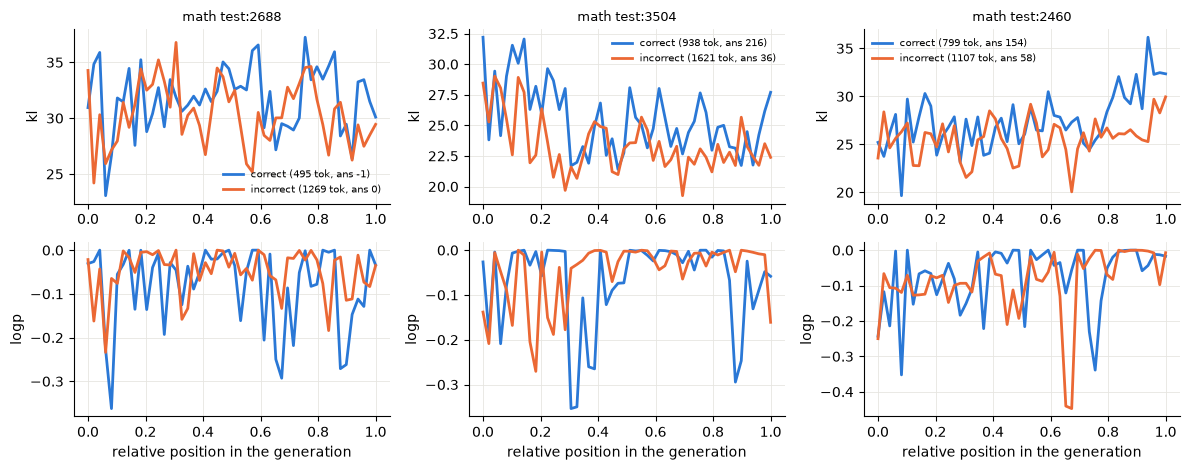

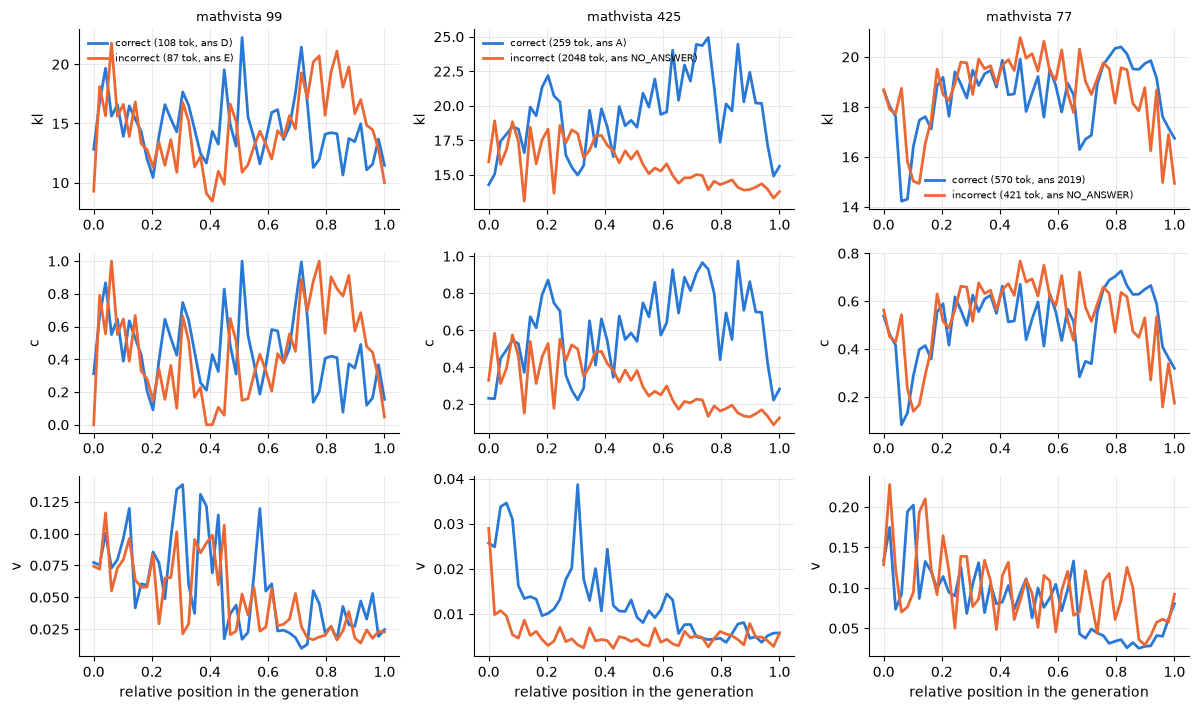

In [17]:
#illustrative trajectories (fixed rule in offline.py -> first 3 mixed evaluation questions per dataset, lowest-id
#correct and incorrect rollout). token signals averaged over 50 equal slices of the generation
traj = load_result('trajectories.json')
series = {'math': ['kl', 'logp'], 'mathvista': ['kl', 'c', 'v']}
for d in DATASETS:
    ts = [t for t in traj if t['dataset'] == d]
    ids = list(dict.fromkeys(t['sample_id'] for t in ts))
    fig, axes = plt.subplots(len(series[d]), len(ids), figsize=(4 * len(ids), 2.4 * len(series[d])), squeeze=False)
    for j, s_id in enumerate(ids):
        for i, key in enumerate(series[d]):
            ax = axes[i, j]
            for t in [t for t in ts if t['sample_id'] == s_id]:
                y = [np.nan if v is None else v for v in t['binned'][key]]
                ax.plot(np.linspace(0, 1, len(y)), y, color='#2a78d6' if t['correct'] else '#eb6834',
                        label=f"{'correct' if t['correct'] else 'incorrect'} ({t['n_tokens']} tok, ans {t['answer'][:12]})")
            ax.set_ylabel(key)
            if i == 0:
                ax.set_title(f'{d} {s_id}', fontsize=9)
                ax.legend(fontsize=7, frameon=False)
            if i == len(series[d]) - 1:
                ax.set_xlabel('relative position in the generation')
    fig.tight_layout()
    fig.savefig(FIGURES / f'trajectories_{d}.png', dpi=200)
    plt.show()

## step 4 -> parallel sampling vs sequential refinement (live, 50 math questions)
the refinement cost includes the shared initial response and the longer revision prompt.

In [18]:
live = load_result('live_summary.json')
live_table = pd.DataFrame(live['strategies']).T
live_table.to_csv(RESULTS / 'table_live.csv')
display(live_table.round(4))
print('refinement transitions (relative to the shared initial answer) ->', live['refinement_transitions'])
display(pd.DataFrame(live['bootstrap']).round(4))
print(f"gpu {live['gpu']}, {live['dtype']}, batch size {live['batch_size']}")

,questions,accuracy,final_answer_extracted_rate,mean_input_tokens,mean_output_tokens,mean_total_tokens,mean_seconds,total_seconds,truncation_rate_of_strategy_calls,extraction_rate_of_strategy_calls,own_calls,own_call_truncation_rate,peak_memory_gb
single,50.0,0.58,0.96,108.38,682.36,790.74,31.6789,1583.9435,0.0400,0.9600,50.0,0.0400,5.8738
parallel,50.0,0.56,0.82,325.14,1852.64,2177.78,85.9299,4296.4969,0.1733,0.8333,150.0,0.1733,5.8047
refinement,50.0,0.62,1.00,885.60,1226.08,2111.68,56.9417,2847.0860,0.0900,0.9200,50.0,0.0000,5.8955


refinement transitions (relative to the shared initial answer) -> {'wrong_to_correct': 2, 'correct_to_wrong': 0, 'correct_to_correct': 29, 'wrong_to_wrong': 19, 'answer_changed': 8}


,strategy,baseline,difference,ci_low,ci_high
0,parallel,single,-0.02,-0.12,0.08
1,refinement,single,0.04,-0.08,0.16
2,refinement,parallel,0.06,0.00,0.14


gpu NVIDIA L4, float16, batch size 1


## step 5 -> adaptive sampling
development grid, the frozen settings, then held-out accuracy, cost and stopping distribution next to fixed-N
self-consistency.

In [19]:
grid = pd.read_csv(RESULTS / 'adaptive_dev_grid.csv')
selected = load_result('adaptive_selected.json')
for d in DATASETS:
    g = grid[grid['dataset'] == d]
    print(NAMES[d], '-> development accuracy (rows tau, columns gamma; agreement = no gamma)')
    q = g[g['family'] == 'quality'].pivot(index='tau', columns='gamma', values='accuracy')
    q.insert(0, 'agreement', g[g['family'] == 'agreement'].set_index('tau')['accuracy'])
    display(q.round(4))
    print('fixed 32 ->', g[g['family'] == 'fixed_32'][['accuracy', 'cost']].round(4).to_dict('records'))
    display(pd.DataFrame(selected[d]).T)

MATH (Qwen2.5-3B) -> development accuracy (rows tau, columns gamma; agreement = no gamma)


gamma,agreement,0.0,0.1,0.25,0.5
tau,,,,,
0.500,0.8145,0.8215,0.8220,0.8210,0.8225
0.625,0.8260,0.8265,0.8265,0.8255,0.8250
0.750,0.8260,0.8265,0.8265,0.8260,0.8245
0.875,0.8260,0.8260,0.8260,0.8260,0.8260
1.000,0.8260,0.8260,0.8260,0.8260,0.8260


fixed 32 -> [{'accuracy': 0.825, 'cost': 18322.4}]


,family,chosen,tau,gamma,dev_accuracy,dev_cost,dev_reference_accuracy
agreement,agreement,agreement,0.625,None,0.826,7088.9555,0.825
quality,quality,quality,0.5,0.0,0.8215,5479.5285,0.825


MathVista (Qwen2.5-VL-3B) -> development accuracy (rows tau, columns gamma; agreement = no gamma)


gamma,agreement,0.0,0.1,0.25,0.5
tau,,,,,
0.500,0.6360,0.6395,0.6395,0.6400,0.6425
0.625,0.6455,0.6445,0.6440,0.6435,0.6435
0.750,0.6440,0.6435,0.6425,0.6425,0.6445
0.875,0.6420,0.6420,0.6420,0.6420,0.6420
1.000,0.6420,0.6420,0.6420,0.6420,0.6420


fixed 32 -> [{'accuracy': 0.6425, 'cost': 9217.485}]


,family,chosen,tau,gamma,dev_accuracy,dev_cost,dev_reference_accuracy
agreement,agreement,agreement,0.5,None,0.636,3705.431,0.6425
quality,quality,quality,0.5,0.0,0.6395,4120.647,0.6425


In [20]:
adaptive = pd.read_csv(RESULTS / 'adaptive_eval.csv')
display(adaptive.round(4))
ab = pd.read_csv(RESULTS / 'adaptive_bootstrap.csv')
display(ab.round(4))
early = pd.read_csv(RESULTS / 'adaptive_early_stops.csv')
orders = cfg['orders']
counts = early.groupby(['dataset', 'policy']).agg(incorrect_early_stops=('order', 'size'),
                                                  recovered_by_fixed_32=('recovered_by_fixed_32', 'sum'),
                                                  questions=('sample_id', 'nunique'))
counts['per_question_order_rate'] = counts['incorrect_early_stops'] / (800 * orders) if not cfg.get('question_limit') else np.nan
display(counts)

,dataset,policy,tau,gamma,accuracy,cost,rollouts,stop_at_4,stop_at_8,stop_at_16,stop_at_32
0,math,fixed_1,NaN,NaN,0.6435,669.7726,1.0000,NaN,NaN,NaN,NaN
1,math,fixed_2,NaN,NaN,0.6435,1339.8655,2.0000,NaN,NaN,NaN,NaN
2,math,fixed_4,NaN,NaN,0.6920,2679.6941,4.0000,1.0000,0.0000,0.0000,0.0000
3,math,fixed_8,NaN,NaN,0.7179,5344.1085,8.0000,0.0000,1.0000,0.0000,0.0000
4,math,fixed_16,NaN,NaN,0.7311,10677.7428,16.0000,0.0000,0.0000,1.0000,0.0000
5,math,fixed_32,NaN,NaN,0.7379,21347.0175,32.0000,0.0000,0.0000,0.0000,1.0000
6,math,agreement,0.625,NaN,0.7364,10139.9810,11.8240,0.6627,0.0586,0.0132,0.2654
7,math,quality,0.500,0.0,0.7318,7663.0554,9.0075,0.7636,0.0581,0.0135,0.1648
8,mathvista,fixed_1,NaN,NaN,0.5360,277.7964,1.0000,NaN,NaN,NaN,NaN
9,mathvista,fixed_2,NaN,NaN,0.5360,551.2501,2.0000,NaN,NaN,NaN,NaN


,dataset,policy,baseline,difference,ci_low,ci_high
0,math,agreement,fixed_1,0.0929,0.0790,0.1075
1,math,agreement,fixed_2,0.0929,0.0790,0.1075
2,math,agreement,fixed_4,0.0444,0.0337,0.0551
3,math,agreement,fixed_8,0.0185,0.0109,0.0270
4,math,agreement,fixed_16,0.0053,-0.0009,0.0118
5,math,agreement,fixed_32,-0.0015,-0.0050,0.0016
6,math,quality,fixed_1,0.0882,0.0750,0.1018
7,math,quality,fixed_2,0.0882,0.0750,0.1018
8,math,quality,fixed_4,0.0398,0.0306,0.0489
9,math,quality,fixed_8,0.0139,0.0075,0.0214


incorrect_early_stops  recovered_by_fixed_32  questions  \
dataset   policy                                                               
math      agreement                    660                     51        160   
          quality                     1152                    131        257   
mathvista agreement                   1966                    344        397   
          quality                     1735                    271        370   

                     per_question_order_rate  
dataset   policy                              
math      agreement                 0.082500  
          quality                   0.144000  
mathvista agreement                 0.245750  
          quality                   0.216875

## step 6 -> compute allocation and failure cases
accuracy against generated tokens with the adaptive policies placed at their observed cost, stopping behaviour
against agreement and the (retrospective) fraction of correct candidates, and whether more samples add new answers.

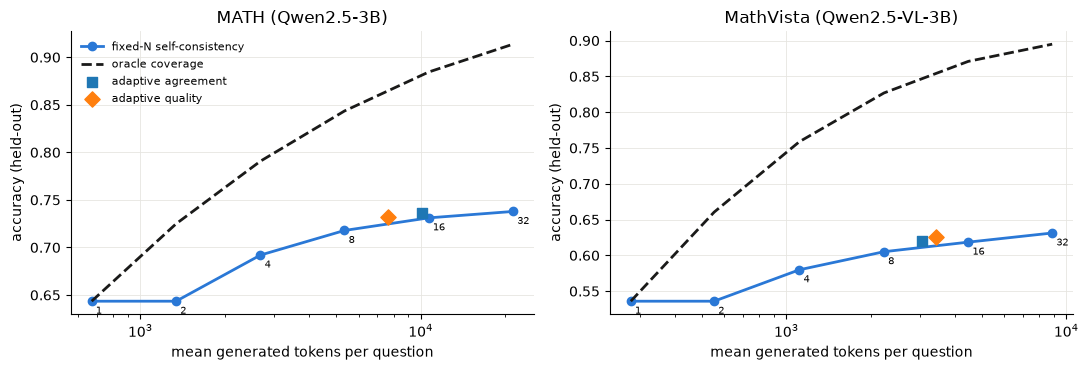

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, d in zip(axes, DATASETS):
    f = adaptive[(adaptive['dataset'] == d) & adaptive['policy'].str.startswith('fixed')]
    ax.plot(f['cost'], f['accuracy'], marker='o', color=COLORS['self_consistency'], label='fixed-N self-consistency')
    for _, r in f.iterrows():
        ax.annotate(r['policy'].split('_')[1], (r['cost'], r['accuracy']), fontsize=7, xytext=(3, -9), textcoords='offset points')
    o = summary_eval[(summary_eval['dataset'] == d) & (summary_eval['method'] == 'self_consistency')]
    ax.plot(o['cost'], o['oracle'], ls='--', color='#1a1a19', label='oracle coverage')
    for policy, marker in [('agreement', 's'), ('quality', 'D')]:
        a = adaptive[(adaptive['dataset'] == d) & (adaptive['policy'] == policy)]
        ax.scatter(a['cost'], a['accuracy'], marker=marker, s=60, zorder=3, label=f'adaptive {policy}')
    ax.set_xscale('log')
    ax.set_xlabel('mean generated tokens per question')
    ax.set_ylabel('accuracy (held-out)')
    ax.set_title(NAMES[d])
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / 'adaptive_cost.png', dpi=200)
plt.show()

In [22]:
#stopping vs the full pool. agreement = plurality share of the 32 rollouts, correct fraction = share of correct
#rollouts among the 32 (retrospective only, never used by a controller)
per_q = pd.read_csv(RESULTS / 'adaptive_per_question.csv')
rows = []
for d in DATASETS:
    groups = load_result(f'answer_groups_{d}.json')
    full = pd.DataFrame([{'sample_id': s, 'plurality_share': max(g['size'] for g in v['groups']) / 32,
                          'correct_fraction': sum(g['size'] for g in v['groups'] if g['correct']) / 32} for s, v in groups.items()])
    t = per_q[per_q['dataset'] == d].merge(full, on='sample_id')
    for col in ['correct_fraction', 'plurality_share']:
        t[f'{col}_bin'] = pd.cut(t[col], [-0.01, 0.25, 0.5, 0.75, 0.999, 1.0], labels=['0 to .25', '.25 to .5', '.5 to .75', '.75 to <1', '1'])
        g = t.groupby(['policy', f'{col}_bin'], observed=True).agg(questions=('sample_id', 'size'), mean_rollouts=('rollouts', 'mean'),
                                                                  accuracy=('accuracy', 'mean')).reset_index()
        g.insert(0, 'dataset', d)
        g = g.rename(columns={f'{col}_bin': 'bin'})
        g.insert(2, 'by', col)
        rows.append(g)
stop_table = pd.concat(rows)
stop_table.to_csv(RESULTS / 'table_stopping_vs_pool.csv', index=False)
display(stop_table.round(3))

,dataset,policy,by,bin,questions,mean_rollouts,accuracy
0,math,agreement,correct_fraction,0 to .25,211,24.855,0.095
1,math,agreement,correct_fraction,.25 to .5,78,21.785,0.768
2,math,agreement,correct_fraction,.5 to .75,74,9.481,0.978
3,math,agreement,correct_fraction,.75 to <1,175,4.377,0.999
4,math,agreement,correct_fraction,1,262,4.000,1.000
5,math,quality,correct_fraction,0 to .25,211,19.134,0.101
6,math,quality,correct_fraction,.25 to .5,78,12.374,0.724
7,math,quality,correct_fraction,.5 to .75,74,5.697,0.962
8,math,quality,correct_fraction,.75 to <1,175,4.194,0.997
9,math,quality,correct_fraction,1,262,4.000,1.000


In [23]:
#do extra samples add alternatives or repeat answers? new groups per doubling and the coverage each doubling adds
rows = []
for d in DATASETS:
    t = step1[step1['dataset'] == d].reset_index(drop=True)
    for i in range(1, len(t)):
        rows.append({'dataset': d, 'from_N': t['N'][i - 1], 'to_N': t['N'][i],
                     'new_groups_per_added_rollout': (t['distinct_groups'][i] - t['distinct_groups'][i - 1]) / (t['N'][i] - t['N'][i - 1]),
                     'coverage_gain': t['oracle_coverage'][i] - t['oracle_coverage'][i - 1],
                     'sc_accuracy_gain': t['sc_accuracy'][i] - t['sc_accuracy'][i - 1]})
growth = pd.DataFrame(rows)
growth.to_csv(RESULTS / 'table_sample_growth.csv', index=False)
display(growth.round(4))

,dataset,from_N,to_N,new_groups_per_added_rollout,coverage_gain,sc_accuracy_gain
0,math,1,2,0.3709,0.0814,0.0000
1,math,2,4,0.2784,0.0659,0.0485
2,math,4,8,0.2032,0.0527,0.0259
3,math,8,16,0.1579,0.0410,0.0133
4,math,16,32,0.1188,0.0292,0.0067
5,mathvista,1,2,0.4534,0.1244,0.0000
6,mathvista,2,4,0.2915,0.0984,0.0439
7,mathvista,4,8,0.1873,0.0681,0.0253
8,mathvista,8,16,0.1181,0.0441,0.0134
9,mathvista,16,32,0.0737,0.0240,0.0127


In [24]:
#representative cases, chosen by fixed rules (no hand picking) ->
#  selection disagreement  first 3 held-out questions (saved permutation order) per dataset where, on order 0 at N = 32,
#                          self-consistency and the quality rule (self-certainty for math, visconf for mathvista)
#                          select different answers and exactly one of them is correct
#  revision                for each refinement transition that occurs, the first live question (live order) showing it
#  premature stopping      first 3 held-out questions per dataset where the quality-aware controller stopped early
#                          on order 0 with a wrong answer that fixed-32 self-consistency gets right
splits = load_result('splits.json')
examples = {'selection_disagreement': [], 'revision': [], 'premature_stopping': []}
for d in DATASETS:
    groups = load_result(f'answer_groups_{d}.json')
    text = pd.read_parquet(DATA / f'rollouts_{d}.parquet', columns=['sample_id', 'rollout_id', 'question_text'])
    text = text[text['rollout_id'] == 0].set_index('sample_id')['question_text']
    sel = pd.read_parquet(RESULTS / f'selections_{d}.parquet')
    sel = sel[(sel['order'] == 0) & (sel['N'] == 32)].set_index('sample_id')
    rule = cfg['adaptive_quality_score'][d]
    key = lambda s, g: groups[s]['groups'][int(g)]['key']
    for s in splits[d]['eval']:
        if s in sel.index and len(examples['selection_disagreement']) < 3 * (DATASETS.index(d) + 1):
            r = sel.loc[s]
            if r['self_consistency'] != r[rule] and r['self_consistency_correct'] != r[f'{rule}_correct']:
                examples['selection_disagreement'].append({
                    'dataset': d, 'sample_id': s, 'question': text[s][:300], 'gold': groups[s]['gold'],
                    'self_consistency': key(s, r['self_consistency']), 'sc_correct': bool(r['self_consistency_correct']),
                    rule: key(s, r[rule]), f'{rule}_correct': bool(r[f'{rule}_correct']),
                    'group_sizes_32': {g['key']: g['size'] for g in groups[s]['groups']}})
    e = early[(early['dataset'] == d) & (early['policy'] == 'quality') & (early['order'] == 0) & early['recovered_by_fixed_32']]
    for s in [s for s in splits[d]['eval'] if s in set(e['sample_id'])][:3]:
        r = e[e['sample_id'] == s].iloc[0]
        examples['premature_stopping'].append({'dataset': d, 'sample_id': s, 'question': text[s][:300], 'gold': groups[s]['gold'],
                                               'stop_n': int(r['stop_n']), 'stopped_answer': key(s, r['stopped_answer_group']),
                                               'fixed_32_answer': key(s, r['fixed_32_answer_group'])})
lq = pd.read_csv(RESULTS / 'live_questions.csv')
ref = lq[lq['strategy'] == 'refinement']
for name, mask in {'wrong_to_correct': ~ref['initial_correct'].astype(bool) & ref['correct'],
                   'correct_to_wrong': ref['initial_correct'].astype(bool) & ~ref['correct'],
                   'changed_wrong_to_wrong': ~ref['initial_correct'].astype(bool) & ~ref['correct'] & (ref['initial_answer'] != ref['answer'])}.items():
    if mask.any():
        r = ref[mask].iloc[0]
        examples['revision'].append({'transition': name, 'sample_id': r['sample_id'], 'initial_answer': r['initial_answer'],
                                     'revised_answer': r['answer']})
(RESULTS / 'examples.json').write_text(json.dumps(examples, indent=2, ensure_ascii=False))
for k, v in examples.items():
    print(k)
    display(pd.DataFrame(v))

selection_disagreement


,dataset,sample_id,question,gold,self_consistency,sc_correct,self_certainty,self_certainty_correct,group_sizes_32,visconf,visconf_correct
0,math,test:1577,How many diagonals are in the fifth polygon of...,14,14,True,5,False,"{'14': 24, '5': 2, '12': 1, '20': 3, '44': 1, ...",NaN,NaN
1,math,test:4702,"Find the integer $n,$ $-90 \le n \le 90,$ such...",59,-59,False,59,True,"{'59': 6, '-59': 10, '-1': 4, 'NO_ANSWER': 3, ...",NaN,NaN
2,math,test:2732,What is the average (mean) of all $5$-digit nu...,\frac{266664}{5},53332.8,True,2222.2,False,"{'53332.8': 7, '54166.47': 2, '1170328': 1, '1...",NaN,NaN
3,mathvista,379,In the diagram of the food web shown what will...,A,A,True,NaN,NaN,"{'A': 28, 'B': 2, 'D': 2}",B,False
4,mathvista,358,Which of the cubes is the same as the unfolded...,A,A,True,NaN,NaN,"{'A': 14, 'E': 5, 'D': 7, 'C': 3, 'B': 3}",D,False
5,mathvista,304,"In the figure above, two line segments meet at...",100,100,True,NaN,NaN,"{'\frac{141 - \sqrt{281}}{2}': 2, '4900': 1, '...",x^2,False


revision


,transition,sample_id,initial_answer,revised_answer
0,wrong_to_correct,test:3504,NO_ANSWER,216
1,changed_wrong_to_wrong,test:2119,NO_ANSWER,21


premature_stopping


,dataset,sample_id,question,gold,stop_n,stopped_answer,fixed_32_answer
0,math,test:1803,"In right triangle $XYZ$, shown below, what is ...",\frac35,8,\frac{4}{5},\frac{3}{5}
1,math,test:3988,If the square root of the length of the hypote...,16,4,4,16
2,math,test:375,"The graphs of two linear functions, $f(x)$ and...",-3,16,0,-3
3,mathvista,434,"In the figure above, side AC of triangle ABC i...",A,4,C,A
4,mathvista,689,Are these people sitting in a circle?\nA. Yes\...,A,4,B,A
5,mathvista,120,What is the degree of this function?,3,4,1,3


## resources

In [25]:
rows = [{'step': 'data preparation (cpu)', 'minutes': prep['seconds'] / 60},
        {'step': 'offline selection + signals (cpu)', 'minutes': load_result('offline_run.json')['seconds'] / 60},
        {'step': 'adaptive simulation (cpu)', 'minutes': load_result('adaptive_run.json')['seconds'] / 60}]
for strategy, s in live['strategies'].items():
    rows.append({'step': f'live -> {strategy} (summed per-call time, initial response included for refinement)',
                 'minutes': s['total_seconds'] / 60, 'peak_memory_gb': s['peak_memory_gb']})
resources = pd.DataFrame(rows)
resources.to_csv(RESULTS / 'resources.csv', index=False)
display(resources.round(3))
print(f"live generation on {live['gpu']}; offline token costs exclude prefill, attention collection and scoring")

,step,minutes,peak_memory_gb
0,data preparation (cpu),7.120,NaN
1,offline selection + signals (cpu),1.513,NaN
2,adaptive simulation (cpu),0.020,NaN
3,"live -> single (summed per-call time, initial ...",26.399,5.874
4,"live -> parallel (summed per-call time, initia...",71.608,5.805
5,"live -> refinement (summed per-call time, init...",47.451,5.895


live generation on NVIDIA L4; offline token costs exclude prefill, attention collection and scoring
